# Car Damage Detection — Step 1: EDA
Dataset: **CarDD** (COCO format). 6 damage types: dent, scratch, crack, glass shatter, lamp broken, tire flat.

Run this notebook from the `notebooks` folder. Install first: `pip install pandas matplotlib seaborn pillow openpyxl`

In [4]:
import json, os
from collections import Counter
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.patches as patches
import seaborn as sns
from PIL import Image

DATA = "../dataset/extracted/CarDD_release/CarDD_COCO"
ANN = f"{DATA}/annotations"
SPLITS = ["train", "val", "test"]
sns.set_theme(style="whitegrid")

In [3]:
%pip install pandas matplotlib seaborn pillow openpyxl

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [seaborn]m2/3 [seaborn]

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Load annotations into tables

In [5]:
img_rows, ann_rows, CATS = [], [], {}
for s in SPLITS:
    d = json.load(open(f"{ANN}/instances_{s}2017.json"))
    CATS = {c["id"]: c["name"] for c in d["categories"]}
    for im in d["images"]:
        img_rows.append({**im, "split": s})
    for a in d["annotations"]:
        x, y, w, h = a["bbox"]
        ann_rows.append({"split": s, "image_id": a["image_id"], "class": CATS[a["category_id"]],
                         "area": a["area"], "x": x, "y": y, "w": w, "h": h, "seg": a["segmentation"]})
imgs, anns = pd.DataFrame(img_rows), pd.DataFrame(ann_rows)
anns = anns.merge(imgs[["id", "split", "width", "height", "file_name"]],
                  left_on=["image_id", "split"], right_on=["id", "split"])
anns["rel_area"] = anns["area"] / (anns["width"] * anns["height"])
anns["aspect"] = anns["w"] / anns["h"].clip(lower=1)
print("Classes:", CATS)
imgs.groupby("split").size().to_frame("images").join(anns.groupby("split").size().to_frame("damages"))

Classes: {1: 'dent', 2: 'scratch', 3: 'crack', 4: 'glass shatter', 5: 'lamp broken', 6: 'tire flat'}


,images,damages
split,,
test,374,785
train,2816,6211
val,810,1744


## 2. Data quality checks

In [6]:
print("Missing image files:")
for s in SPLITS:
    folder = f"{DATA}/{s}2017"
    names = imgs.loc[imgs.split == s, "file_name"]
    missing = [n for n in names if not os.path.exists(f"{folder}/{n}")]
    print(f"  {s}: {len(missing)} of {len(names)}")
no_label = imgs.merge(anns[["image_id","split"]].drop_duplicates(), left_on=["id","split"],
                      right_on=["image_id","split"], how="left", indicator=True)
print("Images with no damage label:", (no_label._merge == "left_only").sum())
print("Duplicate file names across splits:", imgs.file_name.duplicated().sum())
print("Empty / tiny boxes (<10 px side):", ((anns.w < 10) | (anns.h < 10)).sum())

Missing image files:
  train: 67 of 2816
  val: 810 of 810
  test: 0 of 374
Images with no damage label: 0
Duplicate file names across splits: 0
Empty / tiny boxes (<10 px side): 19


## 3. How many of each damage type? (class balance)

split,train,val,test,total,share %
class,,,,,
scratch,2560,728,307,3595,41.1
dent,1806,501,236,2543,29.1
crack,651,177,70,898,10.3
lamp broken,494,141,69,704,8.1
glass shatter,475,135,71,681,7.8
tire flat,225,62,32,319,3.6


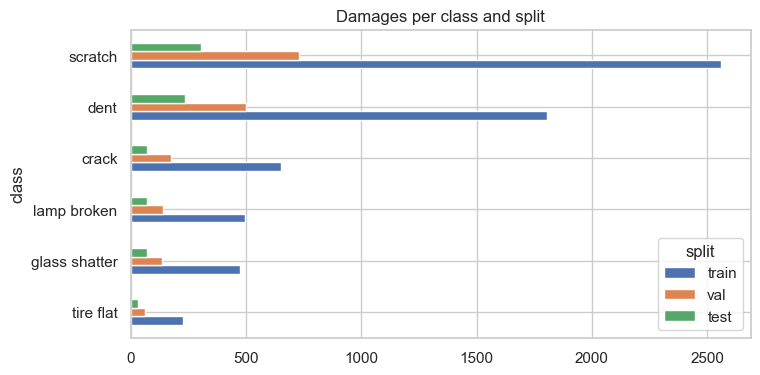

In [7]:
ct = pd.crosstab(anns["class"], anns["split"])[SPLITS]
ct["total"] = ct.sum(axis=1); ct["share %"] = (100 * ct.total / ct.total.sum()).round(1)
display(ct.sort_values("total", ascending=False))
ct[SPLITS].sort_values("train").plot.barh(figsize=(8, 4), title="Damages per class and split"); plt.show()

**Read this:** scratch and dent are most common; tire flat is rare. Rare classes may be detected less well — watch their scores in evaluation.

## 4. Damages per image

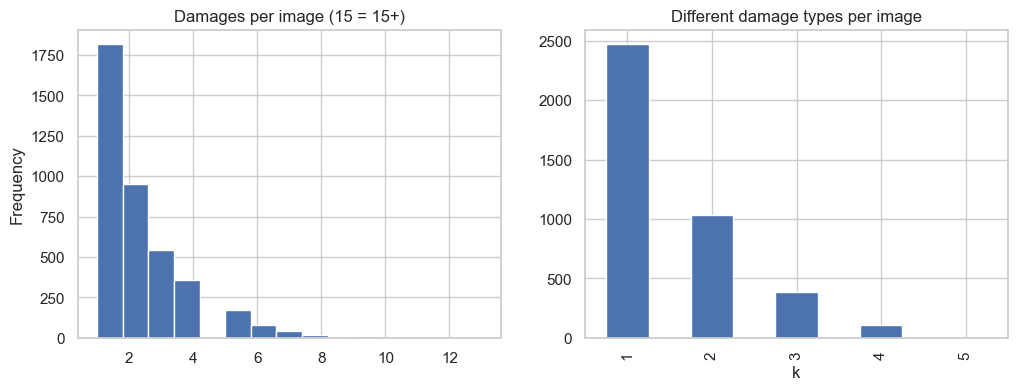

             n        k
count  4000.00  4000.00
mean      2.18     1.54
std       1.53     0.79
min       1.00     1.00
25%       1.00     1.00
50%       2.00     1.00
75%       3.00     2.00
max      13.00     5.00


In [8]:
per_img = anns.groupby(["split", "image_id"]).agg(n=("class", "size"), k=("class", "nunique"))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
per_img.n.clip(upper=15).plot.hist(bins=15, ax=ax[0], title="Damages per image (15 = 15+)")
per_img.k.value_counts().sort_index().plot.bar(ax=ax[1], title="Different damage types per image")
plt.show(); print(per_img.describe().round(2))

## 5. Which damages appear together?

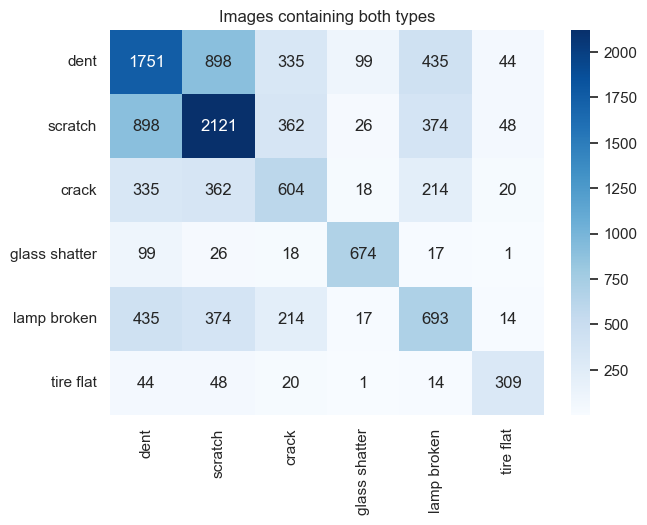

In [9]:
sets = anns.groupby(["split", "image_id"])["class"].apply(set)
names = list(CATS.values())
co = pd.DataFrame(0, index=names, columns=names)
for s in sets:
    for a in s:
        for b in s: co.loc[a, b] += 1
plt.figure(figsize=(7, 5)); sns.heatmap(co, annot=True, fmt="d", cmap="Blues"); plt.title("Images containing both types"); plt.show()

## 6. Image sizes

In [10]:
print(imgs.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))

width  height
1000   667       1969
       750        582
       668        210
667    1000       108
1000   664        100
       662         93
750    1000        84
1000   665         78
       563         69
       666         58
dtype: int64


## 7. Damage size (share of the image area)

size_group,small <1%,medium 1-10%,large >10%
class,,,
crack,86.1,13.4,0.6
dent,11.8,58.4,29.8
glass shatter,0.0,5.7,94.3
lamp broken,2.1,39.3,58.5
scratch,24.2,58.1,17.6
tire flat,0.9,11.0,88.1


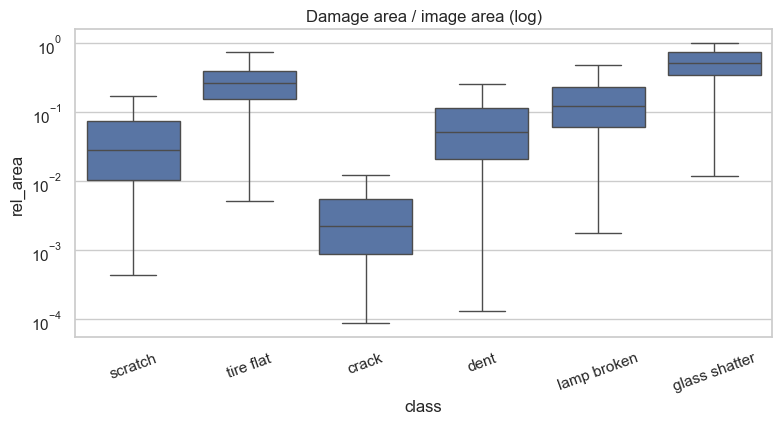

In [11]:
anns["size_group"] = pd.cut(anns.rel_area, [0, 0.01, 0.1, 1], labels=["small <1%", "medium 1-10%", "large >10%"])
display(pd.crosstab(anns["class"], anns["size_group"], normalize="index").mul(100).round(1))
plt.figure(figsize=(9, 4)); sns.boxplot(data=anns, x="class", y="rel_area", showfliers=False)
plt.yscale("log"); plt.title("Damage area / image area (log)"); plt.xticks(rotation=20); plt.show()

**Read this:** 86% of cracks are smaller than 1% of the image — hard to find. Use a large training image size (e.g. 1024).

## 8. Box shape (width / height)

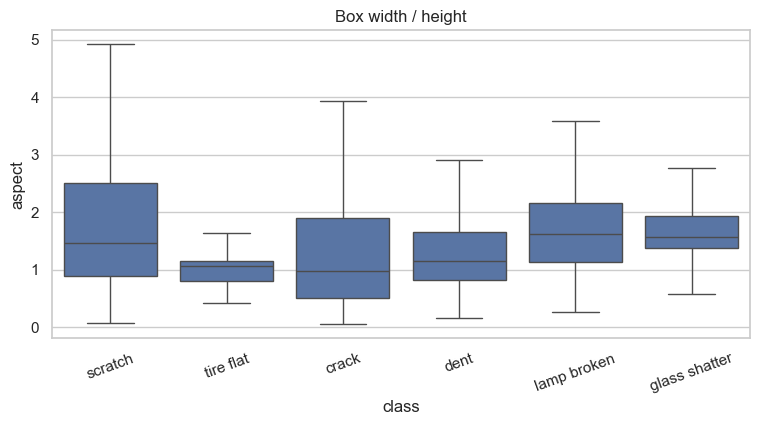

In [12]:
plt.figure(figsize=(9, 4)); sns.boxplot(data=anns, x="class", y="aspect", showfliers=False)
plt.title("Box width / height"); plt.xticks(rotation=20); plt.show()

## 9. Where on the image is the damage?

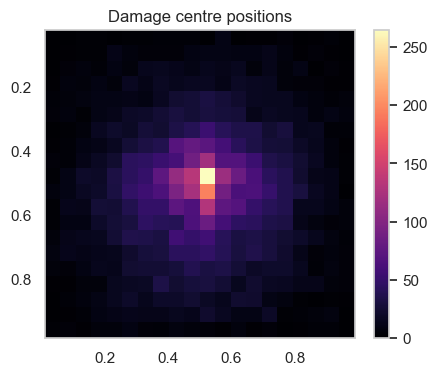

In [13]:
anns["cx"] = (anns.x + anns.w / 2) / anns.width
anns["cy"] = (anns.y + anns.h / 2) / anns.height
plt.figure(figsize=(5, 4)); plt.hist2d(anns.cx, anns.cy, bins=20, cmap="magma")
plt.gca().invert_yaxis(); plt.colorbar(); plt.title("Damage centre positions"); plt.show()

## 10. Photo details (shooting angle, colour, full / partial car)

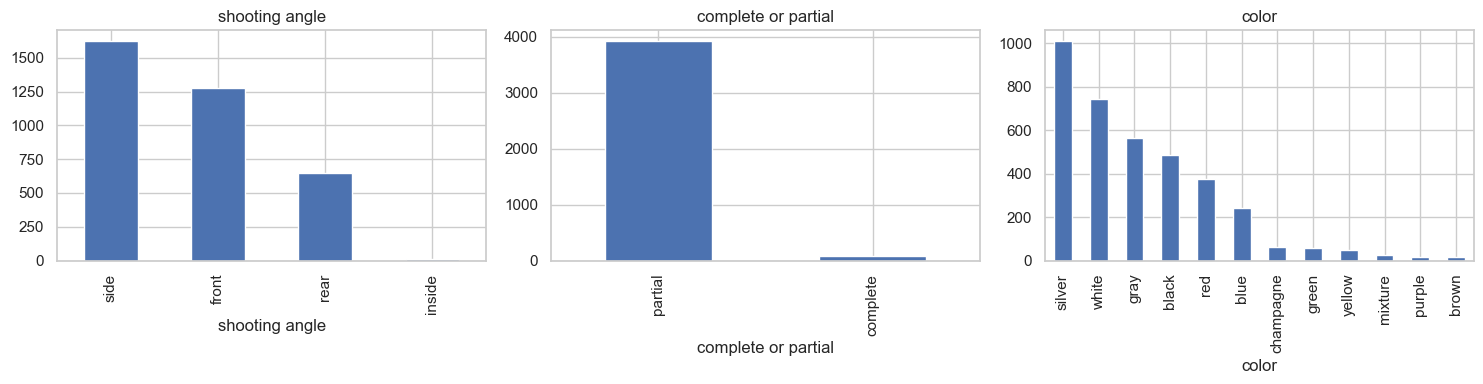

In [14]:
info = pd.read_excel(f"{ANN}/image_info.xlsx")
info.columns = info.columns.str.strip()
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["shooting angle", "complete or partial", "color"]):
    info[col].value_counts().head(12).plot.bar(ax=a, title=col)
plt.tight_layout(); plt.show()

## 11. Look at sample images with their damage outlines

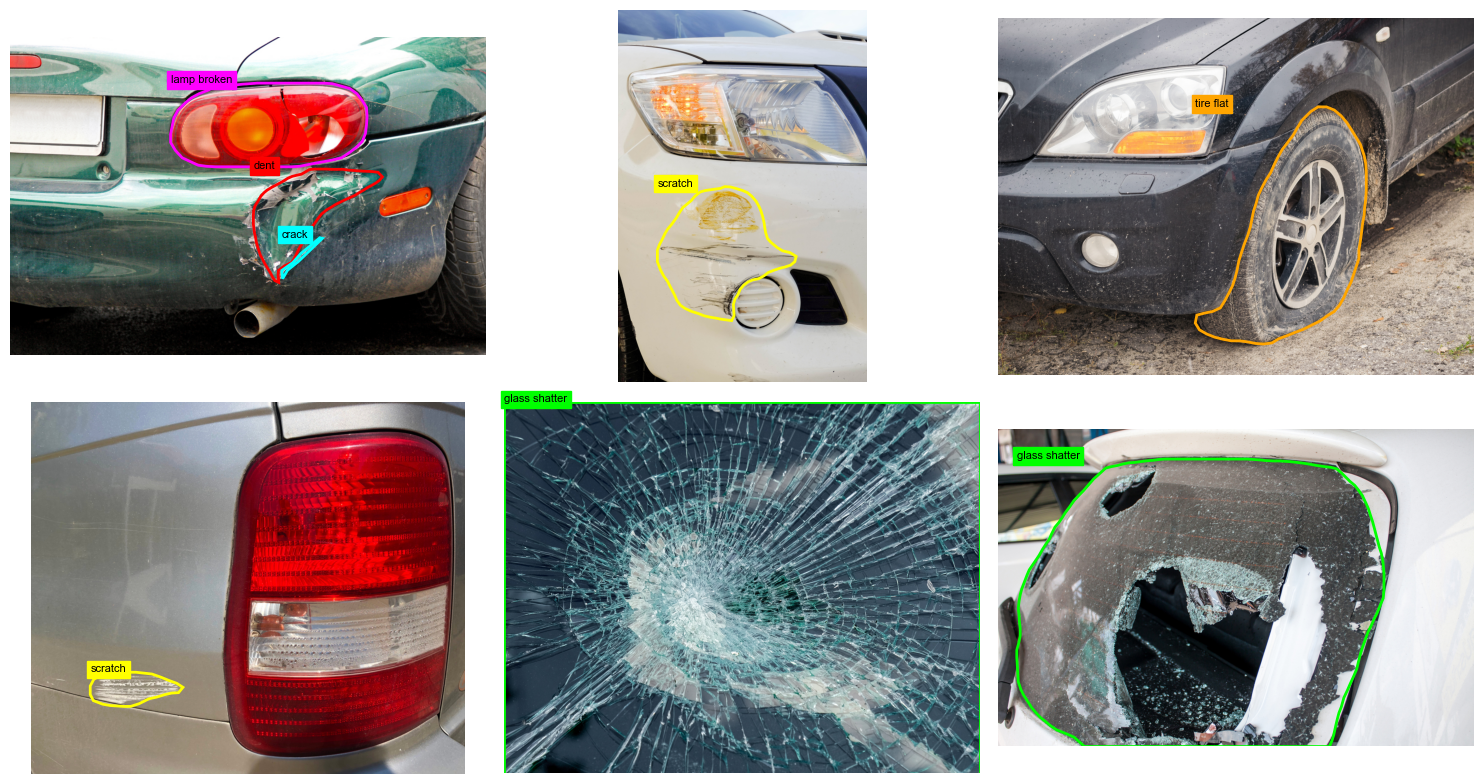

In [15]:
COLORS = dict(zip(CATS.values(), ["red", "yellow", "cyan", "lime", "magenta", "orange"]))
def show(split="train", n=6, cls=None, seed=0):
    pool = anns[anns.split == split]
    if cls: pool = pool[pool["class"] == cls]
    ids = pool.image_id.drop_duplicates().sample(n, random_state=seed)
    fig, axes = plt.subplots(2, n // 2, figsize=(5 * n // 2, 8))
    for ax, iid in zip(axes.flat, ids):
        rows = anns[(anns.split == split) & (anns.image_id == iid)]
        ax.imshow(Image.open(f"{DATA}/{split}2017/{rows.file_name.iloc[0]}"))
        for _, r in rows.iterrows():
            for poly in (r.seg if isinstance(r.seg, list) else []):
                ax.add_patch(patches.Polygon(np.array(poly).reshape(-1, 2), fill=False, ec=COLORS[r["class"]], lw=2))
            ax.text(r.x, r.y, r["class"], color="black", backgroundcolor=COLORS[r["class"]], fontsize=8)
        ax.axis("off")
    plt.tight_layout(); plt.show()
show()

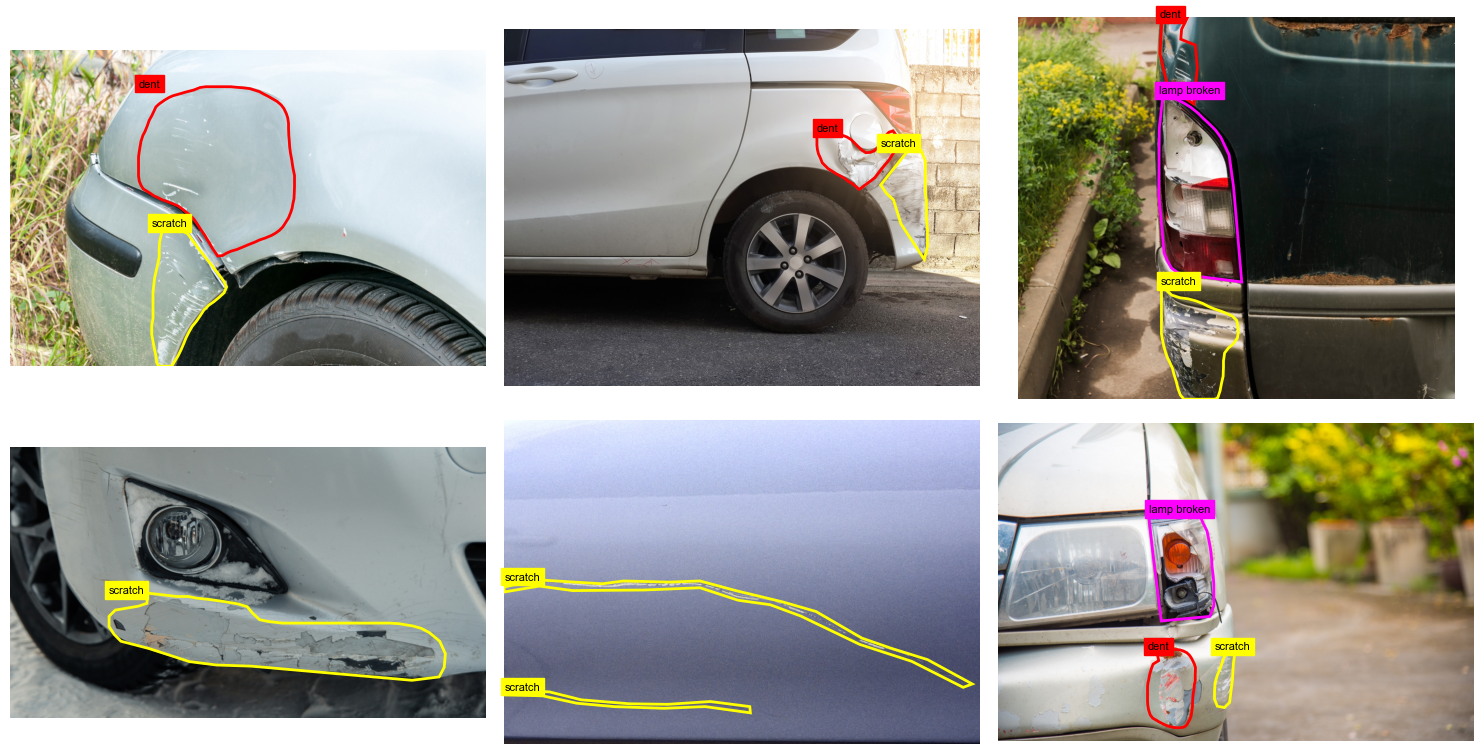

In [16]:
show(cls="scratch")

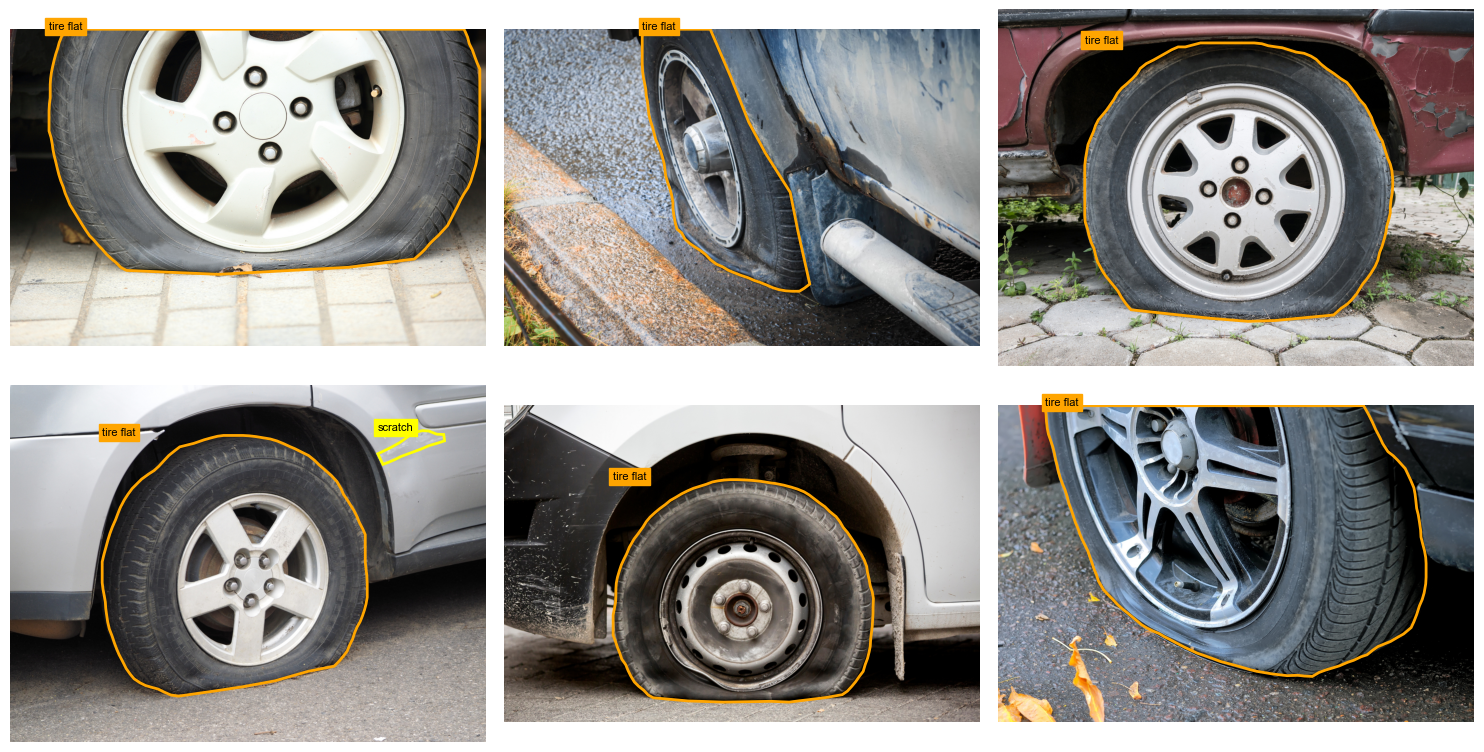

In [17]:
show(cls="tire flat")

## 12. Summary
Run all cells, then note: class balance, share of small damages, any missing files. These guide Step 2 (convert to YOLO) and Step 3 (training settings).